<a href="https://colab.research.google.com/github/amahendra/IoT-UBM-informatics/blob/main/Smart_Building_IoT_Digital_Twin_Read_CSV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on: Smart Building IoT and Digital Twin
### TIC06 | Smart Homes and Buildings | Google Colab

Praktikum ini membaca data CSV yang sudah disediakan untuk memantau enam ruangan pada tiga lantai. Alur: CSV telemetry → simulasi pembacaan BACnet/Modbus → agregasi → Semantic Context → Digital Twin → dashboard → rekomendasi.

**Persiapan:** unduh dan ekstrak paket ZIP, buka notebook di Colab, lalu unggah kelima CSV melalui panel Files (ikon folder di kiri). Jalankan cell secara berurutan. Notebook tidak membuat atau menimpa CSV; seluruh hasil pengolahan berada di memori.

Data sintetis diputar kembali berdasarkan timestamp, bukan data sensor live. BACnet/Modbus direpresentasikan melalui mapping data, bukan komunikasi jaringan. BIM berupa denah dan metadata sederhana, bukan IFC.

## Cell 1. Import library dan lokasi data
Pandas membaca dan mengolah tabel. Matplotlib menampilkan denah dan grafik. File CSV dapat berada di `/content` atau di folder yang sama dengan notebook.

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = '/content' if os.path.isdir('/content') else '.'
print('Folder CSV:', DATA_DIR)

Folder CSV: /content


## Cell 2. Membaca BIM sederhana
Setiap baris mewakili satu ruangan dengan ID, lantai, luas, kapasitas, jenis, dan geometri denah. Room ID menghubungkan ruangan dengan perangkat.

In [ ]:
rooms_df = pd.read_csv(DATA_DIR + '/building_rooms.csv')
display(rooms_df)

,room_id,floor,room_name,area_m2,x_m,y_m,width_m,height_m,capacity_people,room_type
0,R101,1,Lobby,80,0,0,10,8,35,public
1,R102,1,Meeting Room,40,11,0,8,5,12,meeting
2,R201,2,Office A,60,0,0,10,6,18,office
3,R202,2,Office B,60,11,0,10,6,18,office
4,R301,3,Conference Room,100,0,0,12,8,40,meeting
5,R302,3,Server Room,30,13,0,7,5,0,critical


## Cell 3. Membaca daftar perangkat dan mapping protokol

Satu ruangan mempunyai empat titik data: temperature, occupancy, status AC, dan power meter.

- **BACnet simulation:** `analogInput:1` untuk suhu, `analogInput:2` untuk occupancy, dan `binaryValue:3` untuk status AC.
- **Modbus simulation:** `holdingRegister:40001` untuk daya listrik.

Nilai dalam register adalah bilangan bulat. `scale_factor` mengubah nilai mentah menjadi engineering units. Tidak ada pengiriman paket BACnet atau Modbus sungguhan.

In [ ]:
devices_df = pd.read_csv(DATA_DIR + '/building_devices.csv')
display(devices_df.head(8))

,device_id,room_id,measurement,protocol,object_or_register,unit,scale_factor
0,R101-TEMP,R101,temperature_c,BACnet,analogInput:1,C,0.100
1,R101-OCC,R101,occupancy_people,BACnet,analogInput:2,people,1.000
2,R101-AC,R101,hvac_on,BACnet,binaryValue:3,boolean,1.000
3,R101-PWR,R101,power_kw,Modbus,holdingRegister:40001,kW,0.001
4,R102-TEMP,R102,temperature_c,BACnet,analogInput:1,C,0.100
5,R102-OCC,R102,occupancy_people,BACnet,analogInput:2,people,1.000
6,R102-AC,R102,hvac_on,BACnet,binaryValue:3,boolean,1.000
7,R102-PWR,R102,power_kw,Modbus,holdingRegister:40001,kW,0.001


## Cell 4. Membaca telemetry IoT
Data mentah berisi timestamp, device ID, dan raw value. Data sudah disimulasikan sebelumnya dengan interval lima menit. R102 memiliki skenario AC masih aktif setelah meeting; R302 adalah server room yang tetap membutuhkan pendinginan.

In [ ]:
raw_data = pd.read_csv(DATA_DIR + '/iot_sensor_data.csv')
all_times = sorted(raw_data['timestamp'].unique())
TIME_STEPS = len(all_times)
INTERVAL_MINUTES = 5  # Interval data pada CSV yang disediakan
print('Jumlah telemetry:', len(raw_data))
print('Jumlah time steps:', TIME_STEPS)
display(raw_data.head(8))

Jumlah telemetry: 576
Jumlah time steps: 24


,timestamp,device_id,raw_value
0,2026-11-16 08:30:00,R101-TEMP,274
1,2026-11-16 08:30:00,R101-OCC,8
2,2026-11-16 08:30:00,R101-AC,1
3,2026-11-16 08:30:00,R101-PWR,1320
4,2026-11-16 08:30:00,R102-TEMP,287
5,2026-11-16 08:30:00,R102-OCC,0
6,2026-11-16 08:30:00,R102-AC,0
7,2026-11-16 08:30:00,R102-PWR,120


## Cell 5. Membaca BACnet dan Modbus (simulasi mapping)

Di sistem nyata BACnet membaca nilai object dan Modbus membaca nilai register melalui jaringan. Dalam praktikum ini, keduanya direpresentasikan oleh baris CSV. Kita menggabungkan `device_id`, membaca `protocol`, lalu menghitung `value = raw_value × scale_factor`.



In [ ]:
device_info = devices_df
measurements = raw_data.merge(device_info, on='device_id', how='left')
measurements['value'] = measurements['raw_value'] * measurements['scale_factor']
print('BACnet records:',len(measurements[measurements['protocol']=='BACnet']))
print('Modbus records:',len(measurements[measurements['protocol']=='Modbus']))
display(measurements[['timestamp','device_id','protocol','object_or_register','raw_value','value','unit']].head(8))

BACnet records: 432
Modbus records: 144


,timestamp,device_id,protocol,object_or_register,raw_value,value,unit
0,2026-11-16 08:30:00,R101-TEMP,BACnet,analogInput:1,274,27.40,C
1,2026-11-16 08:30:00,R101-OCC,BACnet,analogInput:2,8,8.00,people
2,2026-11-16 08:30:00,R101-AC,BACnet,binaryValue:3,1,1.00,boolean
3,2026-11-16 08:30:00,R101-PWR,Modbus,holdingRegister:40001,1320,1.32,kW
4,2026-11-16 08:30:00,R102-TEMP,BACnet,analogInput:1,287,28.70,C
5,2026-11-16 08:30:00,R102-OCC,BACnet,analogInput:2,0,0.00,people
6,2026-11-16 08:30:00,R102-AC,BACnet,binaryValue:3,0,0.00,boolean
7,2026-11-16 08:30:00,R102-PWR,Modbus,holdingRegister:40001,120,0.12,kW


## Cell 6. Data aggregation: dari device menjadi Room

Empat baris perangkat digabung menjadi satu baris **room state** untuk setiap timestamp. `pivot_table` menempatkan measurement sebagai kolom. Ini penting karena Digital Twin memodelkan ruangan, bukan sekadar mengumpulkan daftar sensor.

In [ ]:
room_data = measurements.pivot_table(index=['timestamp','room_id'],columns='measurement',values='value',aggfunc='last').reset_index()
room_data.columns.name = None
room_data = room_data.merge(rooms_df[['room_id','floor','room_name','room_type','capacity_people','area_m2']],on='room_id')
room_data['occupancy_people'] = room_data['occupancy_people'].astype(int)
room_data['hvac_on'] = room_data['hvac_on'].astype(int)
print('Jumlah room states:',len(room_data))
display(room_data.head(6))

Jumlah room states: 144


,timestamp,room_id,hvac_on,occupancy_people,power_kw,temperature_c,floor,room_name,room_type,capacity_people,area_m2
0,2026-11-16 08:30:00,R101,1,8,1.32,27.4,1,Lobby,public,35,80
1,2026-11-16 08:30:00,R102,0,0,0.12,28.7,1,Meeting Room,meeting,12,40
2,2026-11-16 08:30:00,R201,0,0,0.12,29.1,2,Office A,office,18,60
3,2026-11-16 08:30:00,R202,0,0,0.12,28.3,2,Office B,office,18,60
4,2026-11-16 08:30:00,R301,0,0,0.12,28.7,3,Conference Room,meeting,40,100
5,2026-11-16 08:30:00,R302,1,0,1.12,28.1,3,Server Room,critical,0,30


## Cell 7. Semantic Context
Semantic Context menghubungkan sensor dengan ruangan, lantai, dan HVAC point. Tabel `semantic_relationships.csv` berisi subject, relationship, object. Contoh: `R102-TEMP → observes_room → R102 → served_by_hvac_point → R102-AC`.

Tabel hubungan dibaca dari CSV. Data telemetry diberi konteks melalui penggabungan metadata; query Pandas memilih ruangan kosong dengan HVAC aktif, kecuali ruang kritis. Ini representasi graph sederhana, bukan ontology Brick lengkap.

In [ ]:
semantic_df = pd.read_csv(DATA_DIR + '/semantic_relationships.csv')
print('Jumlah relationships:', len(semantic_df))
display(semantic_df.head(12))

# Telusuri hubungan sensor -> room -> HVAC point dari tabel relationship.
sensor_id = 'R102-TEMP'
room_id = semantic_df.loc[(semantic_df['subject'] == sensor_id) & (semantic_df['relationship'] == 'observes_room'), 'object'].iloc[0]
hvac_point = semantic_df.loc[(semantic_df['subject'] == room_id) & (semantic_df['relationship'] == 'served_by_hvac_point'), 'object'].iloc[0]
print(sensor_id, '->', room_id, '->', hvac_point)

# 2. Membentuk contextualized telemetry dengan menggabungkan hasil Cell 5 dan informasi BIM.
#    Contohnya raw value 253 -> 25.3 C, lalu diketahui berasal dari Meeting Room, Floor 1.
semantic_measurements = measurements.merge(
    rooms_df[['room_id','room_name','floor','room_type']],
    on='room_id', how='left'
)
print('\nContoh sensor dengan Semantic Context:')
display(semantic_measurements[
    (semantic_measurements['device_id']=='R102-TEMP')
][['timestamp','device_id','value','unit','room_id','room_name','floor']].head(3))

# 3. Semantic query: cari ruangan yang kosong tetapi HVAC masih ON.
#    room_data berasal dari data aggregation Cell 6, bukan dari metadata saja.
empty_ac_rooms = room_data[
    (room_data['occupancy_people']==0) &
    (room_data['hvac_on']==1) &
    (room_data['room_type']!='critical')
]
print('\nContoh query: ruangan kosong dan AC ON (non-critical)')
display(empty_ac_rooms[['timestamp','room_id','room_name','floor','occupancy_people','hvac_on']].head(8))



Jumlah relationships: 39


,subject,relationship,object
0,BUILDING-01,has_floor,F1
1,F1,contains_room,R101
2,R101,served_by_hvac_point,R101-AC
3,F1,contains_room,R102
4,R102,served_by_hvac_point,R102-AC
5,BUILDING-01,has_floor,F2
6,F2,contains_room,R201
7,R201,served_by_hvac_point,R201-AC
8,F2,contains_room,R202
9,R202,served_by_hvac_point,R202-AC


R102-TEMP -> R102 -> R102-AC

Contoh sensor dengan Semantic Context:


,timestamp,device_id,value,unit,room_id,room_name,floor
4,2026-11-16 08:30:00,R102-TEMP,28.7,C,R102,Meeting Room,1
28,2026-11-16 08:35:00,R102-TEMP,28.8,C,R102,Meeting Room,1
52,2026-11-16 08:40:00,R102-TEMP,28.9,C,R102,Meeting Room,1



Contoh query: ruangan kosong dan AC ON (non-critical)


,timestamp,room_id,room_name,floor,occupancy_people,hvac_on
109,2026-11-16 10:00:00,R102,Meeting Room,1,0,1
115,2026-11-16 10:05:00,R102,Meeting Room,1,0,1
121,2026-11-16 10:10:00,R102,Meeting Room,1,0,1
127,2026-11-16 10:15:00,R102,Meeting Room,1,0,1
133,2026-11-16 10:20:00,R102,Meeting Room,1,0,1


## Cell 8. Digital Twin state dan rekomendasi
Digital Twin menggabungkan BIM dengan data IoT per timestamp. Riwayat dihitung ulang di memori. Sistem mendeteksi AC aktif di ruangan kosong (kecuali ruang kritis) dan suhu tinggi ketika ruangan berpenghuni. Aturan ini hanya untuk pembelajaran.

In [ ]:
history = room_data.copy()
history['alert'] = 'NORMAL'
history['recommendation'] = 'Monitoring rutin'

for i in range(len(history)):
    row = history.iloc[i]
    if row['hvac_on']==1 and row['occupancy_people']==0 and row['room_type']!='critical':
        history.at[i,'alert']='AC_ON_EMPTY'
        history.at[i,'recommendation']='Periksa AC: ruangan kosong'
    elif row['temperature_c'] > 28.5 and row['occupancy_people'] > 0:
        history.at[i,'alert']='HIGH_TEMPERATURE'
        history.at[i,'recommendation']='Periksa kenyamanan termal'

output_cols=['timestamp','room_id','temperature_c','occupancy_people','hvac_on','power_kw','alert','recommendation']
latest_state = history.sort_values('timestamp').groupby('room_id').tail(1).copy()
print('Digital Twin terbaru:')
display(latest_state[['room_id','room_name','temperature_c','occupancy_people','hvac_on','power_kw','alert']])

Digital Twin terbaru:


,room_id,room_name,temperature_c,occupancy_people,hvac_on,power_kw,alert
142,R301,Conference Room,28.3,0,0,0.12,NORMAL
138,R101,Lobby,24.5,14,1,1.47,NORMAL
139,R102,Meeting Room,24.8,0,0,0.12,NORMAL
140,R201,Office A,26.5,0,0,0.12,NORMAL
141,R202,Office B,26.9,0,0,0.12,NORMAL
143,R302,Server Room,23.5,0,1,1.12,NORMAL


## Cell 9. Dashboard: denah 2D dan tabel status

Kotak mewakili ruangan sesuai BIM sederhana. Warna oranye artinya ada alert; biru artinya normal. Posisi kotak berasal dari koordinat CSV, bukan gambar manual. Untuk melihat kondisi pada waktu berbeda, ganti `VIEW_STEP` dari 0 sampai `TIME_STEPS-1`.

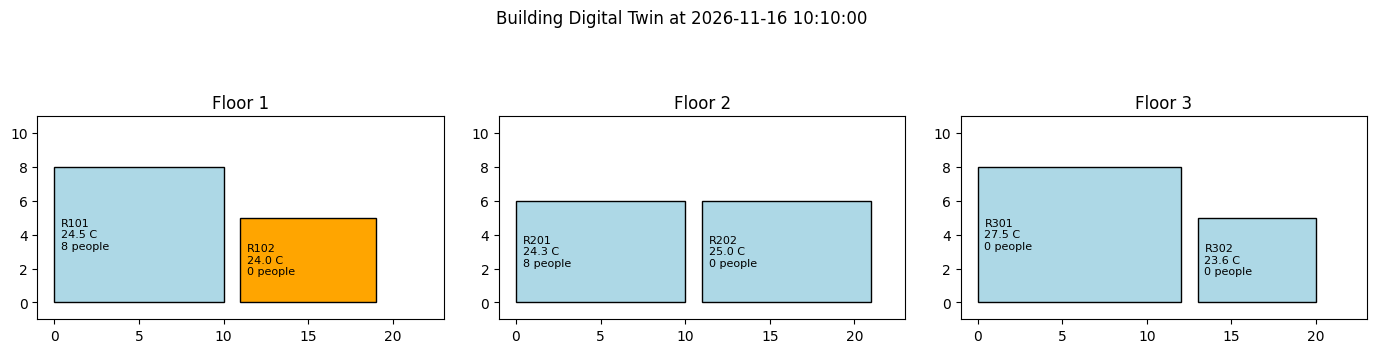

,room_id,room_name,temperature_c,occupancy_people,hvac_on,power_kw,alert
120,R101,Lobby,24.5,8,1,1.32,NORMAL
121,R102,Meeting Room,24.0,0,1,1.12,AC_ON_EMPTY
122,R201,Office A,24.3,8,1,1.32,NORMAL
123,R202,Office B,25.0,0,0,0.12,NORMAL
124,R301,Conference Room,27.5,0,0,0.12,NORMAL
125,R302,Server Room,23.6,0,1,1.12,NORMAL


In [ ]:
from matplotlib.patches import Rectangle
VIEW_STEP = min(20, TIME_STEPS - 1)  # Pilih timestamp yang ditampilkan
all_times = sorted(history['timestamp'].unique())
view_time = all_times[VIEW_STEP]
view_data = history[history['timestamp']==view_time]
fig, axes = plt.subplots(1,3,figsize=(14,4))
for floor in [1,2,3]:
    ax=axes[floor-1]
    floor_rooms=rooms_df[rooms_df['floor']==floor]
    for _,room in floor_rooms.iterrows():
        this = view_data[view_data['room_id']==room['room_id']].iloc[0]
        color='orange' if this['alert']!='NORMAL' else 'lightblue'
        ax.add_patch(Rectangle((room['x_m'],room['y_m']),room['width_m'],room['height_m'],facecolor=color,edgecolor='black'))
        ax.text(room['x_m']+0.4,room['y_m']+room['height_m']/2,
                room['room_id']+'\n'+str(round(this['temperature_c'],1))+' C\n'+str(this['occupancy_people'])+' people',fontsize=8,va='center')
    ax.set_xlim(-1,23);ax.set_ylim(-1,11);ax.set_aspect('equal');ax.set_title('Floor '+str(floor))
plt.suptitle('Building Digital Twin at '+view_time)
plt.tight_layout();plt.show()
display(view_data[['room_id','room_name','temperature_c','occupancy_people','hvac_on','power_kw','alert']])

## Cell 10. Dashboard: grafik konsumsi energi dan suhu

Plot time-series menunjukkan perubahan pada `R102`. Energi dihitung dari power (kW) × durasi 5/60 jam. Untuk perbandingan adil, gunakan time interval yang sama.

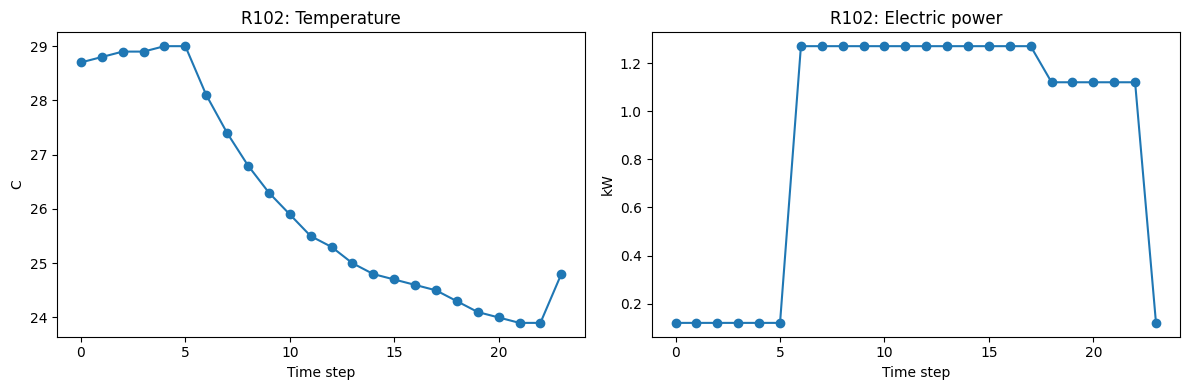

Total simulated R102 energy (kWh): 1.807


In [ ]:
meeting = history[history['room_id']=='R102'].copy()
meeting['step'] = range(len(meeting))
meeting['energy_kwh'] = meeting['power_kw'] * INTERVAL_MINUTES / 60
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(meeting['step'],meeting['temperature_c'],marker='o')
axes[0].set_title('R102: Temperature');axes[0].set_xlabel('Time step');axes[0].set_ylabel('C')
axes[1].plot(meeting['step'],meeting['power_kw'],marker='o')
axes[1].set_title('R102: Electric power');axes[1].set_xlabel('Time step');axes[1].set_ylabel('kW')
plt.tight_layout();plt.show()
print('Total simulated R102 energy (kWh):',round(meeting['energy_kwh'].sum(),3))

## Cell 11. What-if: rekomendasi penghematan energi

Skenario: AC R102 dimatikan saat kosong (setelah meeting). Perbandingan berikut **hanya menghitung energi listrik dari power yang telah disimulasikan**, tidak mensimulasikan kembali temperatur setelah AC dimatikan. Oleh sebab itu hasilnya adalah *energy-only estimate*, bukan klaim penghematan riil atau comfort outcome.

In [ ]:
before_kwh = (meeting['power_kw']*INTERVAL_MINUTES/60).sum()
after_power=[]
for _,row in meeting.iterrows():
    if row['occupancy_people']==0 and row['hvac_on']==1:
        after_power.append(0.12)  # standby load only
    else:
        after_power.append(row['power_kw'])
after_kwh = sum(after_power)*INTERVAL_MINUTES/60
print('Before (kWh):',round(before_kwh,3))
print('After (kWh):',round(after_kwh,3))
print('Energy-only estimate saving (%):',round(100*(before_kwh-after_kwh)/before_kwh,1))
print('CATATAN: kenyamanan termal belum dihitung ulang dalam what-if ini.')

Before (kWh): 1.807
After (kWh): 1.39
Energy-only estimate saving (%): 23.1
CATATAN: kenyamanan termal belum dihitung ulang dalam what-if ini.


## Cell 12. Validasi hasil Digital Twin
File `digital_twin_history.csv` merupakan hasil referensi dari simulasi sebelumnya. Notebook membacanya untuk membandingkan hasil perhitungan baru, tanpa menulis file. Pemeriksaan ini berlaku untuk dataset bawaan.

In [ ]:
reference = pd.read_csv(DATA_DIR + '/digital_twin_history.csv')
assert len(rooms_df) == 6
assert len(devices_df) == 24
assert len(raw_data) == TIME_STEPS * 24
assert len(history) == TIME_STEPS * 6
assert history[['temperature_c','occupancy_people','hvac_on','power_kw']].notna().all().all()
assert not ((history['room_id']=='R302') & (history['alert']=='AC_ON_EMPTY')).any()
assert len(empty_ac_rooms) > 0
assert measurements['room_id'].notna().all()
assert len(semantic_df) == 39
assert semantic_measurements['room_name'].notna().all()
# Bandingkan hasil dengan reference CSV, toleransi untuk angka desimal.
actual = history[output_cols].sort_values(['timestamp','room_id']).reset_index(drop=True)
expected = reference[output_cols].sort_values(['timestamp','room_id']).reset_index(drop=True)
pd.testing.assert_frame_equal(actual, expected, check_dtype=False, check_exact=False, rtol=1e-8, atol=1e-8)
print('11 pemeriksaan berhasil. Hasil cocok dengan CSV referensi.')

11 pemeriksaan berhasil. Hasil cocok dengan CSV referensi.


## Kesimpulan
IoT menyediakan telemetry. Mapping BACnet/Modbus membantu interpretasi nilai perangkat. BIM dan Semantic Context memberi informasi lokasi dan hubungan. Digital Twin mengolah state berdasarkan timestamp untuk visualisasi dan rekomendasi. Semua hasil dihitung di memori; CSV sumber tidak diubah.